In [1]:
%load_ext autoreload
%autoreload 2
    
from domino.data.data import *
from scipy import stats
from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
import matplotlib.pyplot as plt
from domino.utils.tools import seq_from_df
import pandas as pd
import seaborn as sns
import os

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'
import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

from modiscolite.report import generate_tomtom_dataframe
import h5py

import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

from load_modisco import *
from generic_plotting_functions import *
from plot_attributions_and_fimo import *

In [2]:
import json
with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig7_brain/neg_pattern_to_target_dict_adult.json', 'r') as f:
    npatterns2targets = json.load(f)
targets2npatterns = {v[0]:k for k,v in npatterns2targets.items()}

In [3]:
TFMODISCO_WINDOW=600
NUM_FLANKING_BASES=4

model_dir = "/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13_2025_adult_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/"

out_folder = f'{model_dir}/ism_report/'
h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"

pattern_cwms, pattern_ppms = get_pattern_info(h5_file, NUM_FLANKING_BASES)
pattern_attr = get_average_contribution_df(pattern_cwms)

In [4]:
TFMODISCO_WINDOW = 600
modisco_h5py = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
output_dir = f'{model_dir}/tmp'
meme_motif_db = f"{model_dir}/JASPAR2024_CORE_insects_non-redundant_pfms_meme.txt"
is_writing_tomtom_matrix = False 
pattern_groups = ['pos_patterns', 'neg_patterns']
top_n_matches=3
tomtom_exec = "tomtom"
trim_threshold=0.3
trim_min_length=3

results = {'pattern': [], 'num_seqlets': [], 'modisco_cwm_fwd': [], 'modisco_cwm_rev': []}
img_path_suffix = f'{out_folder}/ism_report_{TFMODISCO_WINDOW}bp'
with h5py.File(modisco_h5py, 'r') as modisco_results:
    for name in pattern_groups:
        if name not in modisco_results.keys():
            continue

        metacluster = modisco_results[name]
        key = lambda x: int(x[0].split("_")[-1])
        for pattern_name, pattern in sorted(metacluster.items(), key=key):
            num_seqlets = pattern['seqlets']['n_seqlets'][:][0]
            pattern_tag = f'{name}.{pattern_name}'

            results['pattern'].append(pattern_tag)
            results['num_seqlets'].append(num_seqlets)
            results['modisco_cwm_fwd'].append(os.path.join(img_path_suffix, 'trimmed_logos', f'{pattern_tag}.cwm.fwd.png'))
            results['modisco_cwm_rev'].append(os.path.join(img_path_suffix, 'trimmed_logos', f'{pattern_tag}.cwm.rev.png'))

patterns_df = pd.DataFrame(results)
tomtom_df = generate_tomtom_dataframe(modisco_h5py, output_dir, meme_motif_db, is_writing_tomtom_matrix, pattern_groups)
patterns_df = pd.concat([patterns_df, tomtom_df], axis=1)

final_patterns_df = patterns_df[['pattern', 'num_seqlets', 'match0', 'qval0',	'match1',	'qval1', 'match2',	'qval2']]
avg_attrs = []
for name, cwm in pattern_cwms.items():
    assert(round(cwm['fwd'].mean(), 5) == round(cwm['rev'].mean(), 5))
    avg_attrs.append(cwm['fwd'].sum()/cwm['fwd'].shape[0])

final_patterns_df['avg_attr'] = avg_attrs
final_patterns_df = final_patterns_df.sort_values('avg_attr').reset_index(drop=True)

# get best match to target
from tangermeme.io import read_meme
import logomaker

motifs = read_meme(meme_motif_db)
jaspar2pwm = dict()
for key, pwm in motifs.items():
    motif_code, motif_name = key.split(' ')
    jaspar2pwm[motif_code] = {'pwm': pwm.numpy(), 'name': motif_name}
names = []
for i, row in final_patterns_df.iterrows():
    match = row.match0
    if match in jaspar2pwm:
        name = jaspar2pwm[match]['name']
        names.append(name)
    else:
        names.append(None)
final_patterns_df['target'] = names


/tmp/ipykernel_3755473/3981160771.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_patterns_df['avg_attr'] = avg_attrs


In [5]:
import sys
sys.path.append('../../../python_modules/')
from load_modisco import *
def get_pattern_matrices(out_folder, TFMODISCO_WINDOW, num_flanking_bases):
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases)
    return pattern_cwms, pattern_pwms
 
def compute_total_info_content(pattern):
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic_track = compute_per_position_ic(pattern_pwms[pattern]['fwd'], background, 0.001)
    return ic_track.sum()


def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    ax.set_axis_off()
    if pattern_name and num_seqlets:
        ax.set_title(f'{pattern_name} (num_seqlets={num_seqlets}) {round(q_val,3)}')

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

In [6]:
from tangermeme.io import read_meme
import logomaker
import json

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig7_brain//neg_pattern_to_target_dict_adult.json', 'r') as f:
    npatterns2targets = json.load(f)


out_folder = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13_2025_adult_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/ism_report/'
_, pattern_pwms = get_pattern_matrices(out_folder, 600, num_flanking_bases=4)   
final_patterns_df['total_ic'] = [compute_total_info_content(p) for p in final_patterns_df.pattern]

MIN_NUM_SEQLETS = 100
MAX_ATTR = -0.03
MIN_IC = 7

final_patterns_df_filtered = final_patterns_df.query('num_seqlets > @MIN_NUM_SEQLETS and pattern.str.contains("neg") and avg_attr < @MAX_ATTR and total_ic > @MIN_IC')
final_patterns_df_filtered = final_patterns_df_filtered.sort_values('avg_attr').reset_index(drop=True)
final_patterns_df_filtered['target'] = [npatterns2targets[p][0] for p in final_patterns_df_filtered.pattern]
final_patterns_df_filtered['reference'] = [npatterns2targets[p][1] for p in final_patterns_df_filtered.pattern]


In [7]:
import json
from tangermeme.io import read_meme
import logomaker

motifs = read_meme(meme_motif_db)

jaspar2pwm = dict()
for key, pwm in motifs.items():
    motif_code, motif_name = key.split(' ')
    jaspar2pwm[motif_code] = {
        'pwm': pwm.numpy(),
        'name': motif_name
    }

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig2_motif_discovery/external_ppms.json', 'r') as f:
    target2extppms = json.load(f)
    
def compute_ic(cwm):
    # Normalize columns to probabilities
    probs = cwm / np.sum(cwm, axis=0, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        ic = 2 + np.nansum(probs * np.log2(probs), axis=0)
    return np.sum(ic)  # or np.mean(ic) for mean per position

def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    ax.set_axis_off()
    if pattern_name and num_seqlets:
        ax.set_title(f'{pattern_name} {num_seqlets} {"{:.3e}".format(qval)}')

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

def trim_cwm(cwm, trim_threshold=0.3, FLANKING_BASES=1):
    score = np.sum(np.abs(cwm), axis=1) 
    
    trim_thresh = np.max(score) * trim_threshold 
    pass_inds = np.where(score >= trim_thresh)[0]

    start, end = max(np.min(pass_inds) - FLANKING_BASES, 0), min(np.max(pass_inds) + FLANKING_BASES + 1, len(score) + 1)
    trimmed_cwm = cwm[start:end]
    
    return trimmed_cwm

In [8]:
%matplotlib inline
fig, axes = plt.subplots(len(final_patterns_df_filtered) + 1, 7, figsize=(75, len(final_patterns_df_filtered)*2))
for i, row in final_patterns_df_filtered.iterrows():
    i = i+1
    name = row['pattern']
    target = row['target']
    num_seqlets = row['num_seqlets']
    q_val = row['qval0']
    match = row['match0']
    cwm = pattern_cwms[name]
    trimmed_cwm_fwd = cwm['fwd'] * -1
    ref = row['reference']
    
    if target in ['GTG2', 'su(Hw)', 'AAG3', 'Lola-N', 'GAGA-alt']: 
        trimmed_cwm_fwd = cwm['rev'] * -1
    
    if ref == "JASPAR" or target == 'Motif-8':
        pwm = make_logo(jaspar2pwm[match]['pwm'].T)

    target4ext = target
    if 'Ibf' in target: target4ext = 'Ibf' 
    if 'GAGA' in target: target4ext = 'GAGA2' 
    if 'Motif-7' in target: target4ext = 'Motif-7' 
    
    if target4ext in target2extppms:
        pwm = make_logo(trim_cwm(np.array(target2extppms[target4ext]).T, FLANKING_BASES=3))

    name = target if target != 'UNAM' else f'UNAM{i}'
    final_patterns_df_filtered.loc[i-1, 'target'] = name
    max_val = np.max(final_patterns_df_filtered.avg_attr)
    min_val = np.min(final_patterns_df_filtered.avg_attr)
    avg_attr = row['avg_attr']
    
    plot_weights(trimmed_cwm_fwd, axes[i][1])

    axes[i][3].imshow([[avg_attr]], cmap='Reds_r', vmin = min_val, vmax = max_val, aspect='equal')  # 1x1 square

    for j in [0,2,4,6]:
        axes[i][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[i][0].text(0, 0, i, ha='center', va='center', fontsize=50)
    axes[i][2].text(0, 0, num_seqlets, ha='center', va='center', fontsize=50)
    axes[i][4].text(0, 0, name, ha='center', va='center', fontsize=50)
    
    if ref == 'N/A':
        axes[i][6].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    else:
        axes[i][6].text(0, 0, ref, ha='center', va='center', fontsize=50)
        plot_weights(pwm, axes[i][5])
    
    
    j_vals = [0, 2, 3, 4, 6]
    if ref == 'N/A': j_vals.append(5)
    for j in j_vals:
        axes[i][j].set_xticks([])
        axes[i][j].set_yticks([])
        for spine in axes[i][j].spines.values():
            spine.set_visible(False)
        if j != 3:
            axes[i][j].set_xlim(-0.5, 0.5)
            axes[i][j].set_ylim(-0.5, 0.5)

headers = ['#', 'CWM', 'Count', 'Attribution', 'Motif', 'PWM', 'Source']
for j, header in enumerate(headers):
    axes[0][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[0][j].text(0, 0, header, ha='center', va='center', fontsize=50)
    axes[0][j].set_xticks([])
    axes[0][j].set_yticks([])
    for spine in axes[0][j].spines.values():
        spine.set_visible(False)

# plt.savefig("plots/cwms.pdf", format="pdf")
plt.show()

-0.10030741410963374 -0.034479837918145434


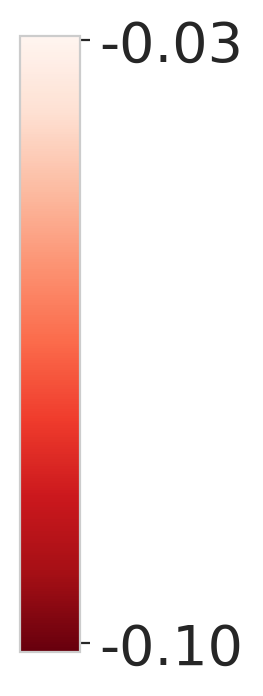

In [9]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Define the colormap and normalization
data = final_patterns_df_filtered.avg_attr.values
vmin, vmax = data.min(), data.max()

p5 = np.percentile(data, 5)
p95 = np.percentile(data, 95)
vmin = np.min(data)
vmax = np.max(data)
print(vmin, vmax)
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(cmap='Reds_r', norm=norm)
sm.set_array([])
fig, ax = plt.subplots(figsize=(1, 4))
fig.subplots_adjust(left=0.5, right=0.8)
cbar = fig.colorbar(sm, cax=ax, ticks=[p5, p95])
cbar.ax.set_yticklabels([f"{p5:.2f}", f"{p95:.2f}"], fontsize=20)
# plt.savefig("plots/colorbar.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()


In [10]:
from tangermeme.io import read_meme
import logomaker
import json

with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig7_brain/neg_pattern_to_target_dict_adult.json', 'r') as f:
    npatterns2targets = json.load(f)
    
MIN_NUM_SEQLETS = 100
MIN_ATTR = 0.01
MIN_IC = 7


final_pos_patterns_df = final_patterns_df.query('num_seqlets > @MIN_NUM_SEQLETS and avg_attr > @MIN_ATTR and pattern.str.contains("pos") and total_ic > @MIN_IC')
final_pos_patterns_df = final_pos_patterns_df.sort_values('avg_attr', ascending=False).reset_index(drop=True)
final_pos_patterns_df['target'] = [npatterns2targets[p][0] for p in final_pos_patterns_df.pattern]
final_pos_patterns_df['reference'] = [npatterns2targets[p][1] for p in final_pos_patterns_df.pattern]

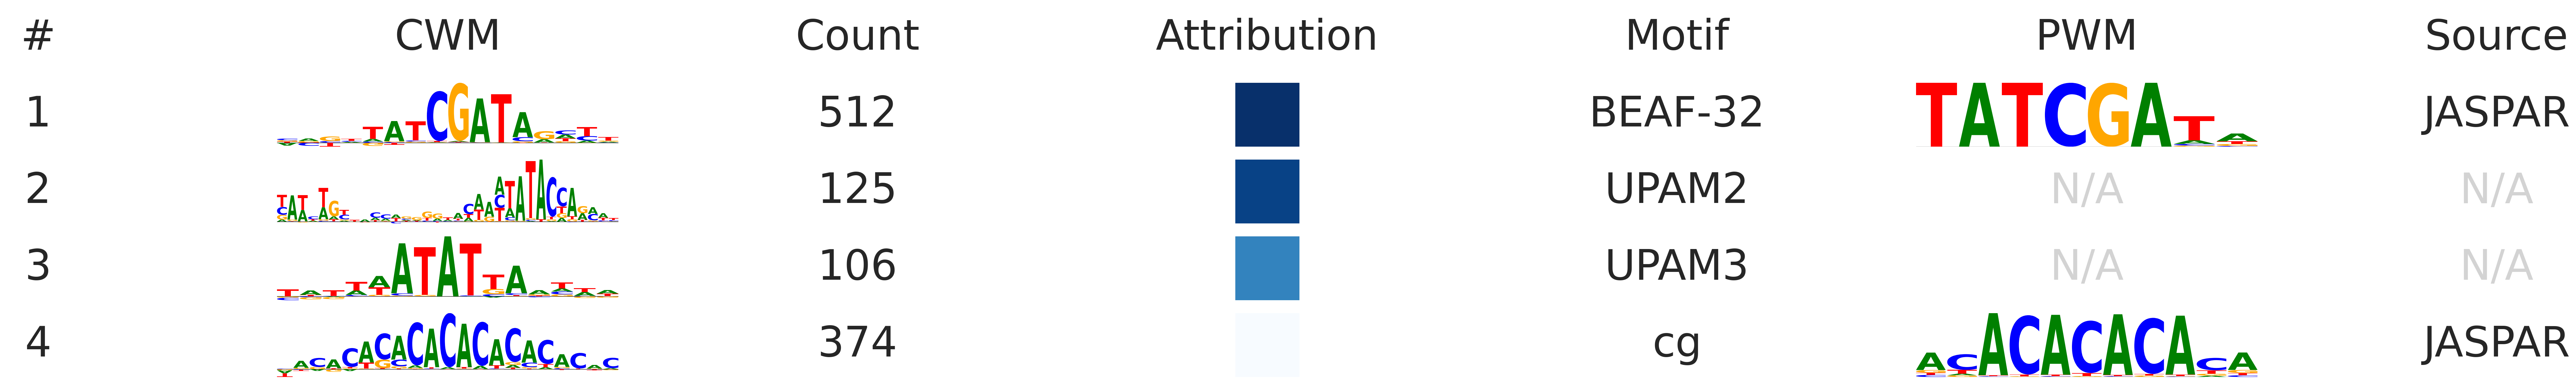

In [13]:
%matplotlib inline
fig, axes = plt.subplots(len(final_pos_patterns_df) + 1, 7, figsize=(60, len(final_pos_patterns_df)*2))
for i, row in final_pos_patterns_df.iterrows():
    i = i+1
    name = row['pattern']
    target = row['target']
    num_seqlets = row['num_seqlets']
    q_val = row['qval0']
    match = row['match0']
    cwm = pattern_cwms[name]
    trimmed_cwm_fwd = cwm['fwd'] 
    ref = row['reference']
    
    if target in ['cg']: 
        trimmed_cwm_fwd = cwm['rev']
    
    if ref == "JASPAR" or target == "CG4854":
        pwm = make_logo(jaspar2pwm[match]['pwm'].T)
    if target in target2extppms:
        pwm = make_logo(trim_cwm(np.array(target2extppms[target]).T, FLANKING_BASES=3))
        
    name = target if target != 'UPAM' else f'UPAM{i}'
    max_val = np.max(final_pos_patterns_df.avg_attr)
    min_val = np.min(final_pos_patterns_df.avg_attr)
    avg_attr = row['avg_attr']
    
    plot_weights(trimmed_cwm_fwd, axes[i][1])

    axes[i][3].imshow([[avg_attr]], cmap='Blues', vmin = min_val, vmax = max_val, aspect='equal')  # 1x1 square

    for j in [0,2,4,6]:
        axes[i][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[i][0].text(0, 0, i, ha='center', va='center', fontsize=50)
    axes[i][2].text(0, 0, num_seqlets, ha='center', va='center', fontsize=50)
    axes[i][4].text(0, 0, name, ha='center', va='center', fontsize=50)
    
    
    if ref == 'N/A':
        axes[i][6].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].text(0, 0, 'N/A', ha='center', va='center', color='#D3D3D3', fontsize=50)
        axes[i][5].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    else:
        axes[i][6].text(0, 0, ref, ha='center', va='center', fontsize=50)
        plot_weights(pwm, axes[i][5])
    
    
    j_vals = [0, 2, 3, 4, 6]
    if ref == 'N/A': j_vals.append(5)
    for j in j_vals:
        axes[i][j].set_xticks([])
        axes[i][j].set_yticks([])
        for spine in axes[i][j].spines.values():
            spine.set_visible(False)
        if j != 3:
            axes[i][j].set_xlim(-0.5, 0.5)
            axes[i][j].set_ylim(-0.5, 0.5)

headers = ['#', 'CWM', 'Count', 'Attribution', 'Motif', 'PWM', 'Source']
for j, header in enumerate(headers):
    axes[0][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
    axes[0][j].text(0, 0, header, ha='center', va='center', fontsize=50)
    axes[0][j].set_xticks([])
    axes[0][j].set_yticks([])
    for spine in axes[0][j].spines.values():
        spine.set_visible(False)

# plt.savefig("plots/positive_cwms.pdf", format="pdf")
plt.show()

0.01940853842720295 0.032068653244323286


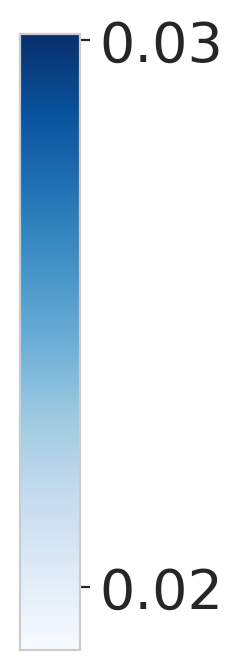

In [14]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Define the colormap and normalization
data = final_pos_patterns_df.avg_attr.values
vmin, vmax = data.min(), data.max()

p5 = np.percentile(data, 5)
p95 = np.percentile(data, 95)
vmin = np.min(data)
vmax = np.max(data)
print(vmin, vmax)
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(cmap='Blues', norm=norm)
sm.set_array([])
fig, ax = plt.subplots(figsize=(1, 4))
fig.subplots_adjust(left=0.5, right=0.8)
cbar = fig.colorbar(sm, cax=ax, ticks=[p5, p95])
cbar.ax.set_yticklabels([f"{p5:.2f}", f"{p95:.2f}"], fontsize=20)
# plt.savefig("plots/positive_colorbar.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

## Clustermap

In [15]:
adult_bound_df = pd.read_csv(f'{model_dir}/final_boundaries_df.bound_score_gt_1.4.nan_offset=20000.stripe_offset=800.csv', index_col=0)
filtered_adult_boundaries_df = adult_bound_df.query('has_stripe_at_bound == False')

In [16]:
ism_dir = os.path.join(model_dir)
ism_attr = np.load(os.path.join(ism_dir, 'windowed_attributions.bound_score_gt_1.4.npy'))

print(ism_attr.shape)

tag2idx = dict()
for i, name in enumerate(pattern_attr.index):
    tag2idx[name] = i + 1

idx2tag = {v:k for k,v in tag2idx.items()}

modisco_results = h5py.File(f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5","r")

seqlets_data = {}
names = ['neg_patterns', 'pos_patterns'] 
for name in names:
    metacluster = modisco_results[name]
    key = lambda x: int(x[0].split("_")[-1])
    for pattern_name, pattern in sorted(metacluster.items(), key=key):
        tag = '{}.{}'.format(name, pattern_name)
        seq_dict = dict()
        for key in pattern['seqlets']:
            seq_dict[key] = pattern['seqlets'][key][:]
        if tag in tag2idx:
            tag = tag2idx[tag] 
        seqlets_data[tag] = seq_dict

modisco_results.close()

(16328, 4, 600)


In [17]:
# counts is how many instances does boundary have of this motif
attr_mat, counts_mat = np.zeros((len(ism_attr), len(pattern_attr))), np.zeros((len(ism_attr), len(pattern_attr)))

# for each pattern in seqlets_data
for pattern_idx, data in seqlets_data.items():
    contrib_scores = data['contrib_scores'] 
    example_idx = data['example_idx']
    
    # for each motif instance, add count
    # also get all trimmed cwm seqlets and get sum of attribution
    for ex_idx, cwm in zip(example_idx, contrib_scores):
        trimmed_cwm = trim_cwm(cwm, trim_threshold=0.3, FLANKING_BASES=1) 
        summed_attr = trimmed_cwm.sum()
        
        attr_mat[ex_idx, pattern_idx - 1] += summed_attr
        counts_mat[ex_idx, pattern_idx - 1] += 1

print('before filtering', attr_mat.shape)
attr_mat = attr_mat[filtered_adult_boundaries_df.index]
print('after filtering', attr_mat.shape)

print('before filtering', counts_mat.shape)
counts_mat = counts_mat[filtered_adult_boundaries_df.index]
print('after filtering', counts_mat.shape)

even_row_sum = counts_mat[0::2]
odd_row_sum = counts_mat[1::2]
counts_mat_combined = even_row_sum + odd_row_sum

even_row_sum = attr_mat[0::2]
odd_row_sum = attr_mat[1::2]
attr_mat_combined = even_row_sum + odd_row_sum

attr_mat_final = attr_mat_combined / 2

print('Number of seqlets for each pattern:')
print(counts_mat_combined.sum(axis=0))

orig_mat = pd.DataFrame(attr_mat_final, columns=final_patterns_df.pattern)
print('clustergram shape (all boundaries > 1.4):', orig_mat.shape)

before filtering (16328, 83)
after filtering (15160, 83)
before filtering (16328, 83)
after filtering (15160, 83)
Number of seqlets for each pattern:
[  68. 2324. 3105. 1661.  756.   22.  686. 1735.   32. 4104. 1054. 1126.
  568.   36.  113.  444.  233. 1187.   41. 1794. 1157. 1329.   86.  155.
 3675.   73. 1182.  525.   27.  137.  367.   27.   21.  209.  662.  385.
   57.   25.  124.  197.   39.  289.  632.  966.  430.   79.  175.   50.
  171.  610. 1034.  995.  269.  194.  182.  114.  121.  326.  232.   37.
  264.  146.  144.  216.  199.   26.   89.   68.  452.   69.   28.  100.
  120.  371.  470.  104.  355.  121.  246.  434.  499. 1933.  262.]
clustergram shape (all boundaries > 1.4): (7580, 83)


In [19]:
final_adult_boundaries_df = filtered_adult_boundaries_df.reset_index(drop=True)
final_adult_boundaries_df

,chrom,start,end,ins_score_1,copy_index_1,ins_score_2,copy_index_2,boundary,demeaned_ins_score_1,demeaned_ins_score_2,direction,pred,bound_score,prop_nan,has_stripe_at_bound
0,chr2L,66801,67000,-1.069563,334,-1.069563,334,1,-0.854763,-0.854763,+,-0.487836,1.437198,0.233286,False
1,chr2L,66801,67000,-1.069563,334,-1.069563,334,1,-0.854763,-0.854763,-,-0.722900,1.437198,0.233286,False
2,chr2L,72201,72400,-0.695531,361,-0.695531,361,1,-0.750259,-0.750259,+,-0.411992,1.723283,0.029628,False
3,chr2L,72201,72400,-0.695531,361,-0.695531,361,1,-0.750259,-0.750259,-,-0.574177,1.723283,0.029628,False
4,chr2L,94601,94800,-0.872936,473,-0.872936,473,1,-0.995644,-0.995644,+,-1.005526,2.003850,0.000000,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15155,chr2R,14981001,14981200,-1.762555,192474,-1.762555,192474,1,-1.866300,-1.866300,-,-1.113281,3.209274,0.000000,False
15156,chr2R,14992201,14992400,-0.868880,192530,-0.868880,192530,1,-1.150118,-1.150118,+,-1.088339,2.851344,0.009925,False
15157,chr2R,14992201,14992400,-0.868880,192530,-0.868880,192530,1,-1.150118,-1.150118,-,-1.120189,2.851344,0.009925,False
15158,chr2R,14993801,14994000,-1.688817,192538,-1.688817,192538,1,-1.931840,-1.931840,+,-1.174510,3.912043,0.009925,False


In [20]:
orig_mat_neg = orig_mat.loc[:, orig_mat.columns.str.contains('neg')]
neg_only_final_patterns_df = final_patterns_df.query('pattern.str.contains("neg")')
# nonzero rows with negative patterns
nonzero_rows_df = orig_mat_neg[(orig_mat_neg != 0).any(axis=1)]

final_neg_motifs = final_patterns_df_filtered.pattern.tolist()



In [22]:
GLOBAL_CUTOFF = -0.25

orig_mat_neg = orig_mat.loc[:, final_neg_motifs]
neg_only_final_patterns_df = final_patterns_df.query('pattern.isin(@final_neg_motifs)')

# nonzero rows
nonzero_rows_df = orig_mat_neg[(orig_mat_neg != 0).any(axis=1)]
# negative rows
negative_rows_df = orig_mat_neg[(orig_mat_neg < 0).any(axis=1)]
# active rows (all boundaries with at least one active motif)
active_rows_df = orig_mat_neg[(orig_mat_neg < GLOBAL_CUTOFF).any(axis=1)]
# # ordering by frequency
freq_ordering = (active_rows_df != 0).sum(axis=0).sort_values(ascending=False).index
# # nonzero rows sorted by frequency of attribution 
active_rows_df_sorted = active_rows_df[freq_ordering]
# all negative boundaries that are active (boolean)
active_rows_boolean_df = active_rows_df_sorted < GLOBAL_CUTOFF

print('Original Matrix:', orig_mat_neg.shape)
print('# Negative Motifs =', neg_only_final_patterns_df.shape[0])
print('Boundaries with nonzero attributions for any negative motif:', nonzero_rows_df.shape)
print('Boundaries with negative attributions for any negative motif:', negative_rows_df.shape)
print('Boundaries with at least one strong negative attribution for any negative motif', active_rows_df.shape)
# print('final matrix with negative motifs only and active rows (boolean)', active_rows_boolean_df.shape)

Original Matrix: (7580, 32)
# Negative Motifs = 32
Boundaries with nonzero attributions for any negative motif: (6281, 32)
Boundaries with negative attributions for any negative motif: (6259, 32)
Boundaries with at least one strong negative attribution for any negative motif (6138, 32)


In [23]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage

def make_final_clustergram(N, cluster_args, filter_active_rows=True, show_clustergram=False):
    row_metric, row_method = cluster_args
    top_N_cols = active_rows_df_sorted.columns[:N]
    clustergram_matrix = active_rows_df_sorted[top_N_cols]
    print('before filtering', clustergram_matrix.shape)
    if filter_active_rows:
        # filter for active rows
        clustergram_matrix = clustergram_matrix[(clustergram_matrix < GLOBAL_CUTOFF).any(axis=1)]
        print('after filtering', clustergram_matrix.shape)

    if show_clustergram:
        row_linkage = linkage(pdist(clustergram_matrix, metric=row_metric), method=row_method)   # DNA: Euclidean + Average
        col_linkage = linkage(pdist(clustergram_matrix.T, metric="cosine"), method="average")  # Proteins: Correlation + Average
        
        g = sns.clustermap(clustergram_matrix, col_cluster=True, row_cluster=True, figsize=(5, 9), 
                           cmap='RdBu', center=0, vmin=-1, vmax=0.25, xticklabels=1, yticklabels=False,
                           row_linkage=row_linkage, col_linkage=col_linkage, dendrogram_ratio=(0, 0.05),
                           cbar_kws={"orientation": "horizontal"})
        
        labs = [label.get_text() for label in g.ax_heatmap.get_xticklabels()]
        g.ax_heatmap.set_xticklabels([npatterns2targets[x] for x in labs], 
                                     rotation=90, fontsize=10)
        
        cbar = g.cax
        cbar.set_position([0.3, 0.1, 0.4, 0.02])  # [left, bottom, width, height]
        cbar.xaxis.set_ticks_position("bottom")
        cbar.xaxis.set_label_position("bottom")
        
        plt.suptitle(f'{row_metric} distance + {row_method} linkage', y=1.005)
        
        plt.show()

    return clustergram_matrix

In [24]:
clustergram_matrix = nonzero_rows_df < GLOBAL_CUTOFF
clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]


In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings
from tqdm import tqdm
warnings.filterwarnings("ignore", category=FutureWarning)

top_N_cols = active_rows_df_sorted.columns
clustergram_matrix = nonzero_rows_df[top_N_cols] < GLOBAL_CUTOFF
clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]
X_scaled = StandardScaler().fit_transform(clustergram_matrix)

inertias = []
K = range(2, 75)

for k in tqdm(K):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_) 

100%|██████████| 73/73 [00:15<00:00,  4.77it/s]


In [25]:

# old_rc = plt.rcParams.copy()
# plt.rcParams['font.size'] = 16

# fig, ax = plt.subplots(1, 1, figsize=(5, 5))
# K = range(2, 75)
# ax.plot(K, inertias, 'bo-', ms=2, c='black')
# # ax.scatter([40], [inertias[39]], c='red', s=5, zorder=4)
# ax.set_xlabel('Number of Clusters (K)')
# ax.set_ylabel('Sum of Squared Distances')
# ax.set_title('Optimal Number of Clusters', fontsize=16)
# ax.set_xlim([1, 74])
# ax.grid(False)
# for spine in ax.spines:  
#     ax.spines[spine].set_color('black')  
#     ax.spines[spine].set_linewidth(1)  # Decrease spine thickness
# plt.show()
# plt.rcParams.update(old_rc)

In [26]:
# from matplotlib.colors import ListedColormap
# from matplotlib.cm import get_cmap
# import matplotlib.patches as patches
# import matplotlib.patches as mpatches
# from sklearn.cluster import KMeans
# from sklearn.preprocessing import StandardScaler

# # GENERATE LABELS

# for K in np.arange(32, 42):

#     clustergram_matrix = nonzero_rows_df < GLOBAL_CUTOFF
#     clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]
#     # clustergram_matrix = nonzero_rows_df[top_N_cols].loc[clustergram_matrix.index]
  
#     X_scaled = StandardScaler().fit_transform(clustergram_matrix)
    
#     kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
#     kmeans.fit(X_scaled)  
    
#     labels = kmeans.labels_
#     labels = pd.Series(labels)
    
#     cluster_sizes = labels.value_counts().sort_values(ascending=False)
#     label_map = {old: new for new, old in enumerate(cluster_sizes.index)}
#     new_labels = labels.map(label_map)
    
#     sorted_labels = new_labels.sort_values()
#     sorted_idxs = sorted_labels.index
    
#     # print(labels.shape)
#     # print(sorted_labels.shape)
#     # print(sorted_idxs.shape)
#     # print(sorted_idxs.max())
    
#     # GENERATE CLUSTERMAP
    
#     top_N_cols = active_rows_df_sorted.columns
#     clustergram_matrix = active_rows_df_sorted[top_N_cols]
#     print('before filtering', clustergram_matrix.shape)
#     clustergram_matrix_filtered = clustergram_matrix[(clustergram_matrix < GLOBAL_CUTOFF).any(axis=1)]
#     print('after filtering', clustergram_matrix_filtered.shape)
#     clustergram_sorted_matrix = clustergram_matrix_filtered.iloc[sorted_idxs]
    
#     tmp = clustergram_sorted_matrix.copy()
#     tmp['cluster'] = sorted_labels.tolist()
    
#     grouped = tmp.groupby('cluster')
#     # column_order = ['neg_patterns.pattern_5', 'neg_patterns.pattern_13', 'neg_patterns.pattern_14'] + [targets2npatterns[t] for t in promoter_motifs] + [targets2npatterns[t] for t in non_promoter_motifs]
#     # used_columns = set(column_order)
#     column_order = []
#     used_columns = set()
#     for cat in sorted(labels.unique()):
#         # for each cluster, count the number of elements with number of active boundaries across all columns
#         col_sums = (grouped.get_group(cat) < GLOBAL_CUTOFF).sum()
#         sorted_cols = col_sums.sort_values(ascending=False).index.tolist() 
#         # print(npatterns2targets[sorted_cols[0]])
#         if sorted_cols[0] not in ['cluster'] and sorted_cols[0] not in used_columns:
#             column_order.append(sorted_cols[0])
#             used_columns.add(sorted_cols[0])
#     column_order.extend(list(set(top_N_cols) - set(column_order)))
            
#     tmp['row_sum'] = tmp.drop(columns='cluster').sum(axis=1)
#     sorted_df = (
#         tmp.sort_values(['cluster', 'row_sum'], ascending=[True, True]).drop(columns=['row_sum', 'cluster'])
#     )
#     clustergram_sorted_matrix = sorted_df
#     # clustergram_sorted_matrix = sorted_df.loc[tmp.sort_values(['cluster', 'row_sum']).query('cluster == 0').index]
#     clustergram_sorted_matrix = clustergram_sorted_matrix[column_order]
#     # clustergram_sorted_matrix['cluster'] = sorted_labels.values
#     # row_linkage = linkage(pdist(clustergram_matrix, metric=row_metric), method=row_method)   # DNA: Euclidean + Average
#     # col_linkage = linkage(pdist(clustergram_sorted_matrix.T, metric="cosine"), method="average")  # Proteins: Correlation + Average
    
    
#     tab20_colors = list(plt.get_cmap('tab20').colors)
#     set3_colors = sns.color_palette("Set3", 25)
#     colors_K = tab20_colors + set3_colors
#     cluster_colors = colors_K
    
    
#     # cmap_K = ListedColormap(colors_K, name="distinct_K")
#     col_colors = sorted_labels.map(lambda x: colors_K[x]).tolist()
    
#     vmin, vmax=-1, 0.25
#     g = sns.clustermap(clustergram_sorted_matrix, col_cluster=False, row_cluster=False, figsize=(6, 12), 
#                        cmap='RdBu', center=0, vmin=vmin, vmax=vmax, xticklabels=1, yticklabels=False,
#                        dendrogram_ratio=(0, 0.05), rasterized=True,
#                        cbar_kws={"orientation": "horizontal"}, row_colors=col_colors)  # discrete color annotations on columns)
    
#     xlabs = [label.get_text() for label in g.ax_heatmap.get_xticklabels()]
#     g.ax_heatmap.set_xticklabels([final_patterns_df_filtered.query('pattern == @x').target.item() for x in xlabs], 
#                                  rotation=90, fontsize=10)
#     g.ax_heatmap.xaxis.set_ticks_position('top')        # Move ticks to top
#     g.ax_heatmap.xaxis.set_label_position('top')        # Move axis label to top (if any)
#     g.ax_heatmap.tick_params(axis='x', bottom=False, length=2)
#     g.ax_heatmap.set_xlabel('')  # Hide x-axis label
    
#     # vertical lines between columns
#     for x in range(1, clustergram_sorted_matrix.shape[1]):
#         g.ax_heatmap.axvline(x, color='gray', lw=0.03)
        
#     cbar = g.cax
#     cbar.set_position([0.3, 0.15, 0.4, 0.015])  # [left, bottom, width, height]
#     pos = g.ax_row_colors.get_position().bounds
#     new_pos = [pos[0] - 0.06, pos[1], pos[2] + 0.05, pos[3]]  # double the width, for example
#     g.ax_row_colors.set_position(new_pos)
    
#     row_groups = sorted_labels.reset_index(drop=True)
#     row_colors = pd.Series(colors_K[:K])
#     row_colors.index = np.arange(K)
#     ordered_groups = row_groups
#     boundaries = ordered_groups[ordered_groups != ordered_groups.shift(1)].index.tolist()
#     for b in boundaries[1:]:
#         g.ax_heatmap.hlines(b - 0.5, *g.ax_heatmap.get_xlim(), colors='black', linewidth=0.5, alpha=0.8)
    
#     cbar.set_xticks([-1, 0.25])
#     # cbar.set_xticklabels([f'{vmin:.2f}', f'{vmax:.2f}'])
#     cbar.xaxis.set_ticks_position("bottom")
#     cbar.xaxis.set_label_position("bottom")
#     # cbar.set_title("Total Attribution", fontsize=10)  # use set_label() for vertical colorbars
#     cbar.set_xlabel("Total Attribution", labelpad=-5)
#     for spine in cbar.spines.values():
#         spine.set_visible(True)
#         spine.set_edgecolor('black')
#         spine.set_linewidth(0.5)
    
#     # Add bounding box around the heatmap
#     pos = g.ax_heatmap.get_position()
#     rect = patches.Rectangle(
#         (pos.x0, pos.y0),           # lower-left corner
#         pos.width, pos.height,      # width and height
#         linewidth=0.75,
#         alpha=0.8,
#         edgecolor='black',
#         facecolor='none',
#         transform=g.fig.transFigure,  # figure coordinates
#         zorder=10
#     )
#     g.fig.patches.append(rect)
    
    
#     unique_groups = list(row_groups.unique())
#     cluster_sizes = sorted_labels.value_counts()
#     # cluster_ids = {grp: f'{cluster2names[str(i)]} ({str(i)})' for i, grp in enumerate(unique_groups)}
#     cluster_ids = {grp: f'{grp} (n={cluster_sizes[i]})' for i, grp in enumerate(unique_groups)}
#     # cluster_ids = {grp: f'{grp}' for i, grp in enumerate(unique_groups)}
    
#     # Figure out the y position (in axes fraction) of each group in the color strip
#     n_rows = len(ordered_groups)
#     group_y_frac = {}
    
#     for grp in unique_groups:
#         members = ordered_groups[ordered_groups == grp].index.tolist()
#         if members:
#             avg_index = sum(members) / len(members)
#             y_frac = 1 - (avg_index / n_rows)  # top = 1
#             group_y_frac[grp] = y_frac
        
        
#     # Plot labels and lines directly on the row_colors axis
#     ax = g.ax_row_colors
    
#     for grp in unique_groups:
#         y = group_y_frac[grp]
#         color = row_colors[grp]
#         label = cluster_ids[grp]
    
#         # Draw line from color patch to label
#         ax.annotate(
#             '', xy=(0.0, y), xycoords='axes fraction',
#             xytext=(0.0, y), textcoords='axes fraction',
#             # arrowprops=dict(arrowstyle='-', lw=1, color='black')
#         )
    
#         # Add text label
#         fontsize = 8 if grp >= 19 else 10
#         ax.text(
#             -0.25, y, label,
#             transform=ax.transAxes,
#             va='center', ha='right',
#             fontsize=fontsize, color='black'
#         )
    
#     plt.suptitle(f'K={K}', y=1.04)
#     # plt.savefig("plots/clustergram.pdf", format="pdf", dpi=300, bbox_inches='tight')
#     plt.show()

before filtering (6138, 32)
after filtering (6138, 32)


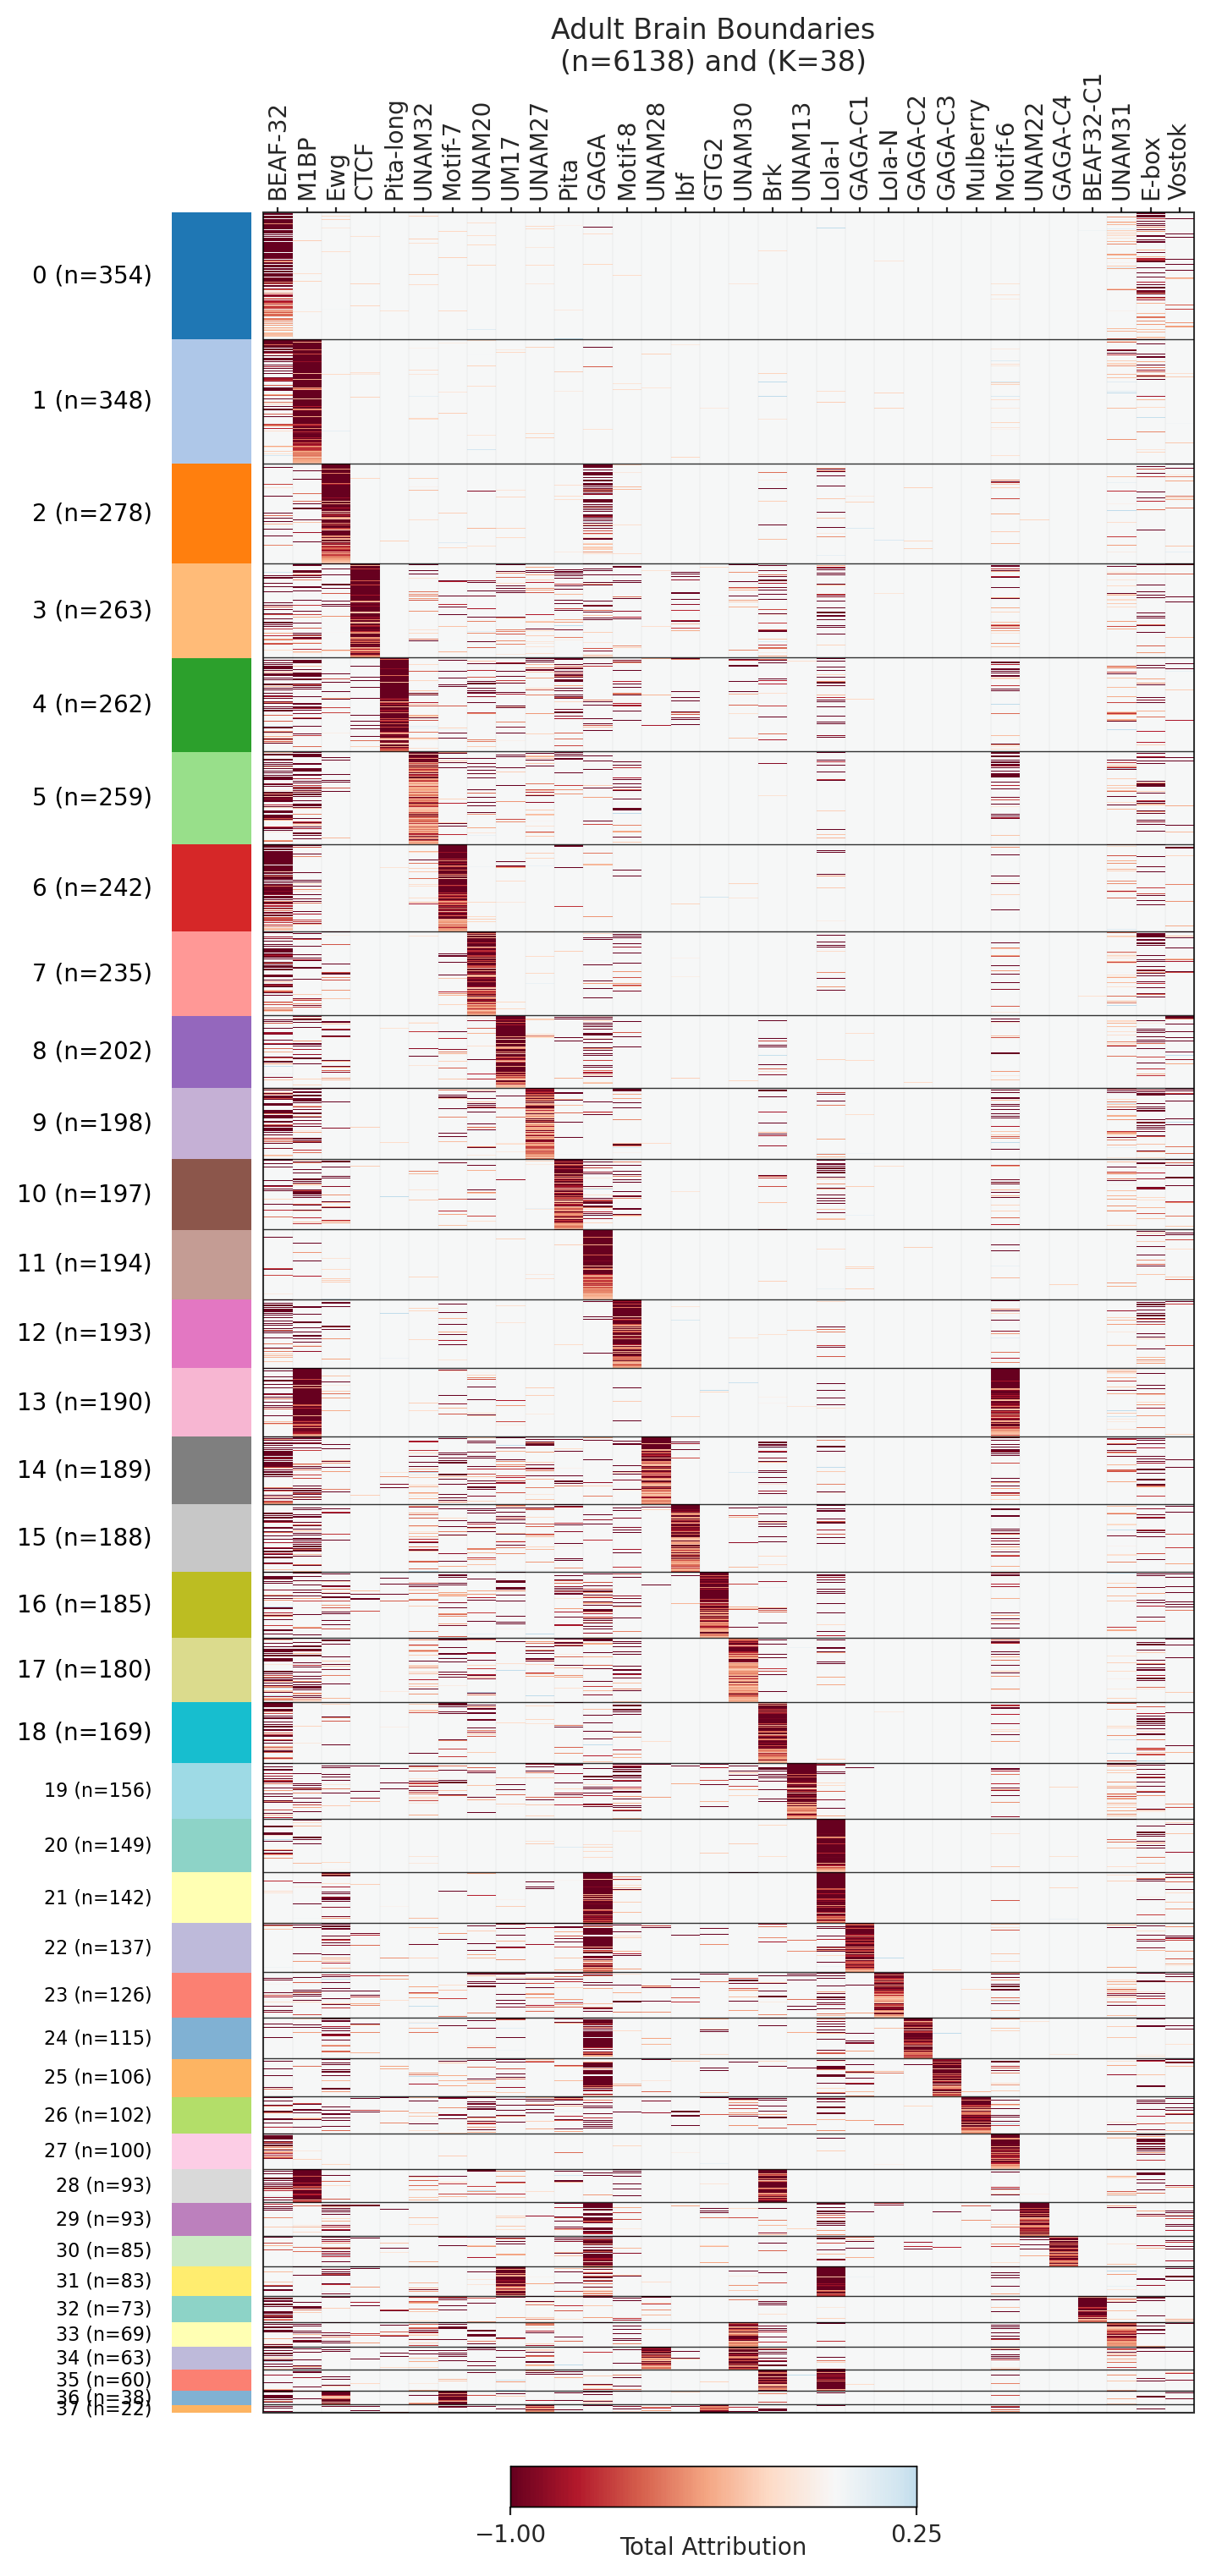

In [26]:

from matplotlib.colors import ListedColormap
from matplotlib.cm import get_cmap
import matplotlib.patches as patches
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# GENERATE LABELS

K=38

clustergram_matrix = nonzero_rows_df < GLOBAL_CUTOFF
clustergram_matrix = clustergram_matrix[(clustergram_matrix != 0).any(axis=1)]
# clustergram_matrix = nonzero_rows_df[top_N_cols].loc[clustergram_matrix.index]

X_scaled = StandardScaler().fit_transform(clustergram_matrix)

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(X_scaled)  

labels = kmeans.labels_
labels = pd.Series(labels)

cluster_sizes = labels.value_counts().sort_values(ascending=False)
label_map = {old: new for new, old in enumerate(cluster_sizes.index)}
new_labels = labels.map(label_map)

sorted_labels = new_labels.sort_values()
sorted_idxs = sorted_labels.index


# GENERATE CLUSTERMAP

top_N_cols = active_rows_df_sorted.columns
clustergram_matrix = active_rows_df_sorted[top_N_cols]
print('before filtering', clustergram_matrix.shape)
clustergram_matrix_filtered = clustergram_matrix[(clustergram_matrix < GLOBAL_CUTOFF).any(axis=1)]
print('after filtering', clustergram_matrix_filtered.shape)
clustergram_sorted_matrix = clustergram_matrix_filtered.iloc[sorted_idxs]

tmp = clustergram_sorted_matrix.copy()
tmp['cluster'] = sorted_labels.tolist()

grouped = tmp.groupby('cluster')
column_order = []
used_columns = set()
for cat in sorted(labels.unique()):
    # for each cluster, count the number of elements with number of active boundaries across all columns
    col_sums = (grouped.get_group(cat) < GLOBAL_CUTOFF).sum()
    sorted_cols = col_sums.sort_values(ascending=False).index.tolist() 
    if sorted_cols[0] not in ['cluster'] and sorted_cols[0] not in used_columns:
        column_order.append(sorted_cols[0])
        used_columns.add(sorted_cols[0])
column_order.extend(list(set(top_N_cols) - set(column_order)))
        
tmp['row_sum'] = tmp.drop(columns='cluster').sum(axis=1)
sorted_df = (
    tmp.sort_values(['cluster', 'row_sum'], ascending=[True, True]).drop(columns=['row_sum', 'cluster'])
)
clustergram_sorted_matrix = sorted_df
clustergram_sorted_matrix = clustergram_sorted_matrix[column_order]

tab20_colors = list(plt.get_cmap('tab20').colors)
set3_colors = sns.color_palette("Set3", 25)
colors_K = tab20_colors + set3_colors
cluster_colors = colors_K


col_colors = sorted_labels.map(lambda x: colors_K[x]).tolist()

vmin, vmax=-1, 0.25
height = 16
g = sns.clustermap(clustergram_sorted_matrix, col_cluster=False, row_cluster=False, figsize=(6, height), 
                   cmap='RdBu', center=0, vmin=vmin, vmax=vmax, xticklabels=1, yticklabels=False,
                   dendrogram_ratio=(0, 0.05), rasterized=True,
                   cbar_kws={"orientation": "horizontal"}, row_colors=col_colors)  # discrete color annotations on columns)

xlabs = [label.get_text() for label in g.ax_heatmap.get_xticklabels()]
g.ax_heatmap.set_xticklabels([final_patterns_df_filtered.query('pattern == @x').target.item() for x in xlabs], 
                             rotation=90, fontsize=10)
g.ax_heatmap.xaxis.set_ticks_position('top')        # Move ticks to top
g.ax_heatmap.xaxis.set_label_position('top')        # Move axis label to top (if any)
g.ax_heatmap.tick_params(axis='x', bottom=False, length=2)
g.ax_heatmap.set_xlabel('')  # Hide x-axis label

for x in range(1, clustergram_sorted_matrix.shape[1]):
    g.ax_heatmap.axvline(x, color='gray', lw=0.03)
    
cbar = g.cax
cbar.set_position([0.3, 0.1, 0.4, 0.015])  # [left, bottom, width, height]
pos = g.ax_row_colors.get_position().bounds
new_pos = [pos[0] - 0.06, pos[1], pos[2] + 0.05, pos[3]]  # double the width, for example
g.ax_row_colors.set_position(new_pos)

row_groups = sorted_labels.reset_index(drop=True)
row_colors = pd.Series(colors_K[:K])
row_colors.index = np.arange(K)
ordered_groups = row_groups
boundaries = ordered_groups[ordered_groups != ordered_groups.shift(1)].index.tolist()
for b in boundaries[1:]:
    g.ax_heatmap.hlines(b - 0.5, *g.ax_heatmap.get_xlim(), colors='black', linewidth=0.5, alpha=0.8)

cbar.set_xticks([-1, 0.25])
# cbar.set_xticklabels([f'{vmin:.2f}', f'{vmax:.2f}'])
cbar.xaxis.set_ticks_position("bottom")
cbar.xaxis.set_label_position("bottom")
# cbar.set_title("Total Attribution", fontsize=10)  # use set_label() for vertical colorbars
cbar.set_xlabel("Total Attribution", labelpad=-5)
for spine in cbar.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('black')
    spine.set_linewidth(0.5)

pos = g.ax_heatmap.get_position()
rect = patches.Rectangle(
    (pos.x0, pos.y0),           # lower-left corner
    pos.width, pos.height,      # width and height
    linewidth=0.75,
    alpha=0.8,
    edgecolor='black',
    facecolor='none',
    transform=g.fig.transFigure,  # figure coordinates
    zorder=10
)
g.fig.patches.append(rect)


unique_groups = list(row_groups.unique())
cluster_sizes = sorted_labels.value_counts()
cluster_ids = {grp: f'{grp} (n={cluster_sizes[i]})' for i, grp in enumerate(unique_groups)}

n_rows = len(ordered_groups)
group_y_frac = {}

for grp in unique_groups:
    members = ordered_groups[ordered_groups == grp].index.tolist()
    if members:
        avg_index = sum(members) / len(members)
        y_frac = 1 - (avg_index / n_rows)  # top = 1
        group_y_frac[grp] = y_frac
    
    
ax = g.ax_row_colors

for grp in unique_groups:
    y = group_y_frac[grp]
    color = row_colors[grp]
    label = cluster_ids[grp]

    # Draw line from color patch to label
    ax.annotate(
        '', xy=(0.0, y), xycoords='axes fraction',
        xytext=(0.0, y), textcoords='axes fraction',
    )

    # Add text label
    fontsize = 8 if grp >= 19 else 10
    ax.text(
        -0.25, y, label,
        transform=ax.transAxes,
        va='center', ha='right',
        fontsize=fontsize, color='black'
    )

plt.suptitle(f'Adult Brain Boundaries\n(n={len(clustergram_sorted_matrix)}) and (K={K})', y=1.02)
# plt.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/clustergram.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

## Pairwise co-activity

In [27]:
import itertools
import scipy
from statsmodels.stats.multitest import multipletests

def pairwise_coactivity_dataframe(attribution_df, CUTOFF):
    if 'cluster' in attribution_df: 
        attribution_df = attribution_df.drop('cluster', axis=1)
    active_rows_boolean_df = attribution_df  < CUTOFF
    print('all rows that contain at least one nonzero negative attribution', active_rows_boolean_df.shape)
    print('among all rows that contain at least one active negative motif in top 20 list, boolean df', active_rows_boolean_df.shape)
    
    column_pairs = list(itertools.combinations(active_rows_boolean_df.columns, 2))
    
    results = []
    for col1, col2 in column_pairs:
        # if col1.split('.')[0] != col2.split('.')[0]:
        has_active_motif1 = (active_rows_boolean_df[col1] > 0)
        has_active_motif2 = (active_rows_boolean_df[col2] > 0)
        no_active_motif1 = ~has_active_motif1
        no_active_motif2 = ~has_active_motif2
        odds, p = scipy.stats.fisher_exact([
            [(has_active_motif1 & has_active_motif2).sum(), (has_active_motif1 & no_active_motif2).sum()],
            [(no_active_motif1 & has_active_motif2).sum(), (no_active_motif1 & no_active_motif2).sum()]
        ], alternative='greater')
        fraction = (has_active_motif1 & has_active_motif2).mean()
        results.append([fraction, 
                        final_patterns_df_filtered.query('pattern == @col1').target.item(), 
                        final_patterns_df_filtered.query('pattern == @col2').target.item(), odds, p])
    
    results = pd.DataFrame(results, columns = ['fraction_co_activate', 'motif_name1',
                                               'motif_name2', 'odds', 'p'])
    # results['significance'] = -np.log10(results['p'])
    results['log_odds'] = np.log10(results['odds'])
    results['idx'] = np.arange(len(results))
    
    ALPHA = 5e-2
    _, pvals_corrected, _, _ = multipletests(results['p'], alpha=ALPHA, method='fdr_bh')
    results['bh_corrected_p'] = pvals_corrected
    results['significance'] = -np.log10(results['bh_corrected_p'])
    return results

In [28]:
adult_results = pairwise_coactivity_dataframe(negative_rows_df, -0.25)


all rows that contain at least one nonzero negative attribution (6259, 32)
among all rows that contain at least one active negative motif in top 20 list, boolean df (6259, 32)


/home/byw2/micromamba/envs/domino_vis/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


Index([157, 407, 409, 410, 411, 414, 442, 444, 460, 461, 471, 477], dtype='int64')


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


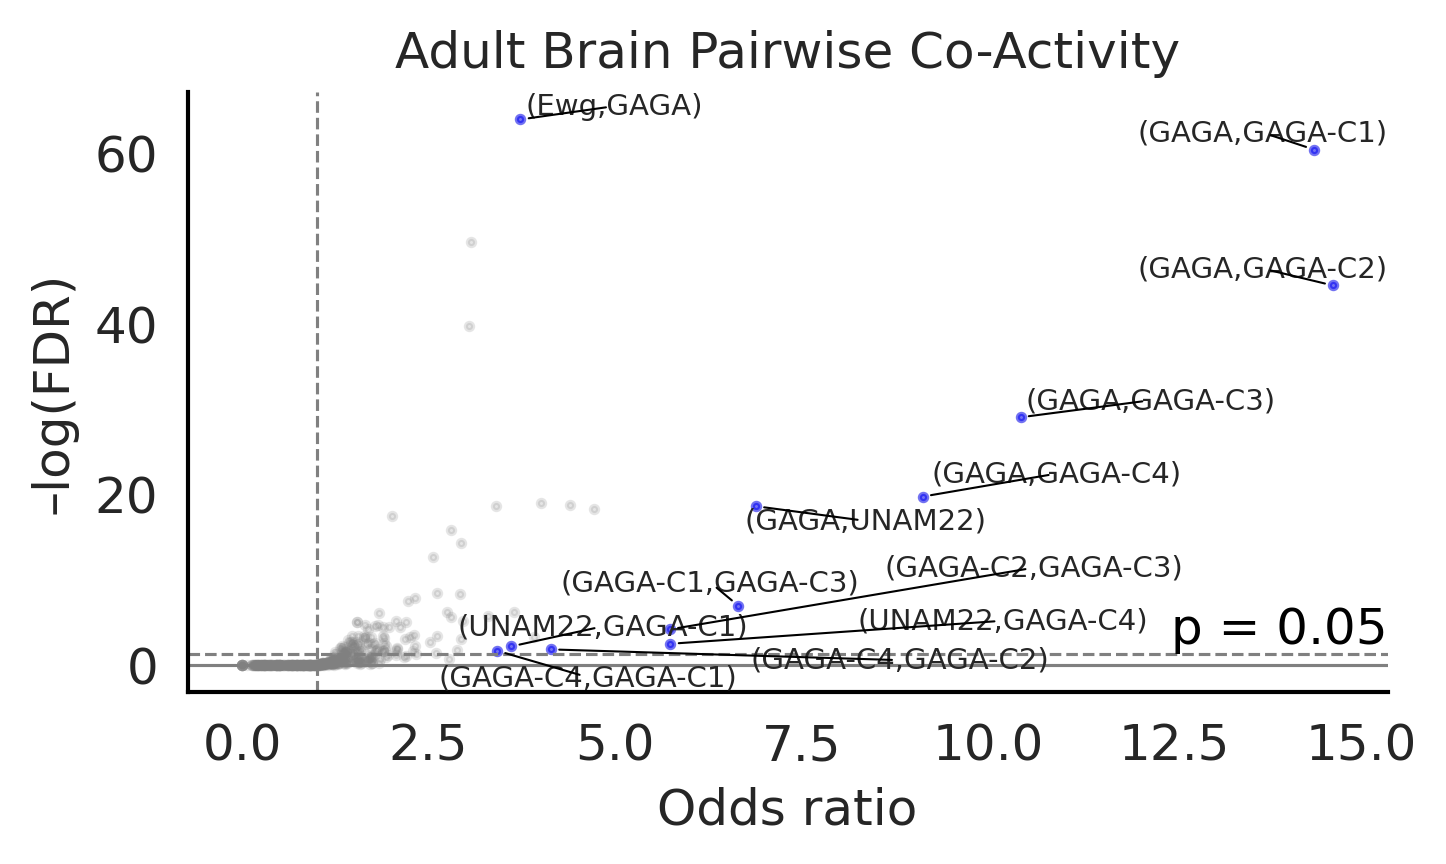

In [29]:
old_rc = plt.rcParams.copy()
plt.rcParams['font.size'] = 12

from adjustText import adjust_text

ALPHA=0.05
OR_CUTOFF = 3
SIG_CUTOFF=2.5

fig, ax = init_subplots_exact(1, 1, sharey=True, dpi=300, y_ratios=[0.5], xspace=1.1)
plt.sca(ax)

x, y = adult_results['odds'], adult_results['significance']
plt.scatter(x, y, s=3, alpha=0.2, color='gray')
plt.xlabel('Odds ratio')
plt.axvline(1, linewidth=0.75, color='gray', linestyle='dashed')
plt.axhline(0, linewidth=0.75, color='gray', linestyle='solid')
# plt.axvline(OR_CUTOFF, linewidth=0.5, color='gray', linestyle='dashed')
plt.axhline(-np.log10(ALPHA), linewidth=0.75, color='gray', linestyle='dashed')
plt.ylabel(f"–log(FDR)")
plt.title('Pairwise Motif Co-Activity', fontsize=12)
ax.grid(False)
ax.spines[['right', 'top']].set_visible(False)
ax.text(x=1, y=-np.log10(ALPHA)*1.1, s=f'p = {ALPHA}', color='black',
        ha='right', va='bottom', fontsize=12,
        transform=ax.get_yaxis_transform())

annotate_indices = adult_results.query('bh_corrected_p < 0.05 and odds > @OR_CUTOFF and (motif_name1.str.contains("GAGA") or motif_name2.str.contains("GAGA"))').index
print(annotate_indices)

labels = [f'({i},{j})' for i,j in zip(adult_results.motif_name1, adult_results.motif_name2)]
texts = []
for i in annotate_indices:
    xi, yi = x[i], y[i]
    text = ax.text(xi, yi, labels[i], fontsize=7, zorder=3)
    texts.append(text)
    plt.scatter(x[i], y[i], s=3, alpha=0.5, color='#0000ff')

adjust_text(
    texts,
    x=x, y=y,
    ax=ax,
    force_text=(2, 2),
    force_points=(5, 5),
    explode_radius=100,
    lim=1000,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=0.5,
    ),
)

for spine in ['left', 'bottom']:  
    ax.spines[spine].set_color('black')  
    ax.spines[spine].set_linewidth(1)  # Decrease spine thickness

ax.set_title("Adult Brain Pairwise Co-Activity", fontsize=12)

plt.show()

plt.rcParams.update(old_rc)
